### Wintervorrat – Lösung Schritt für Schritt

*36. Bundeswettbewerb Informatik (2017), 1. Runde, Junioraufgabe 2*

Das kleine Eichhörnchen Fritz wohnt im Rechteckwald, einem rechteckigen Gebiet bestehend aus Feldern.

Fritz sucht einen Platz, an dem er seine Wintervorräte vergraben kann. Das Vergraben benötigt Zeit, und in dieser Zeit darf
Fritz nicht von einem Raubvogel erspäht werden. Fritz hat bereits ausgekundschaftet, wie sich die Raubvögel im Rechteckwald
üblicherweise verhalten.

Ab dem ersten Sonnenstrahl beginnen die Vögel nach und nach, über den Wald zu fliegen. Alle fliegen parallel zu den Seiten
des Waldes. Manche fliegen zwischen West- und Ostrand, andere zwischen Nord- und Südrand des Waldes hin und her. Dabei halten
sie nach Beute Ausschau: Sie überblicken kurz das Feld, über dem sie sich befinden, und dann fliegen sie zum nächsten Feld
weiter. Das dauert insgesamt eine Minute. Die Sonne scheint genau 12 Stunden. Nur in dieser Zeit können die Vögel Beute erspähen.

Am liebsten hätte Fritz ein absolut sicheres Feld, das nie von einem Vogel überblickt wird. Es kann allerdings sein, dass es
ein solches Feld nicht gibt. Das ist aber nicht schlimm, denn Fritz braucht nur 30 Minuten, um seine Vorräte zu vergraben.
Deswegen genügt ihm auch ein sicheres Feld: Ein Feld ist sicher, wenn es am Tag einen sicheren Zeitraum von 30 Minuten
gibt, in denen kein Vogel das Feld überblicken kann.

#### Junioraufgabe 2

Schreibe ein Programm für Fritz. Gegeben sind die Größe des Rechteckwaldes, die Anzahl der Vögel und für jeden Vogel dessen
Startfeld, -zeitpunkt und -flugrichtung. Das Startfeld ist ein Randfeld, und jeder Vogel fliegt von dort aus in der
gegebenen Richtung zum gegenüberliegenden Randfeld und wieder zurück.

1. Das Programm soll zunächst entscheiden, ob es absolut sichere Felder gibt. Wenn ja, soll es sie ausgeben.
2. Außerdem soll das Programm sichere Felder finden, falls möglich, und für jedes dieser Felder einen sicheren Zeitraum
   ausgeben. Dazu kann das Programm simulieren, wie die Vögel während des Tages den Wald überfliegen.

Wende dein Programm auf die Beispiele an, die du auf den BwInf-Webseiten findest.

#### Beispieldaten

Im Ordner `beispieldaten` stehen `wintervorrat1.txt` bis `wintervorrat6.txt`. Jede Datei ist so aufgebaut:

- 1. Zeile: Breite und Höhe des Waldes (West-Ost-Richtung, Nord-Süd-Richtung)
- 2. Zeile: Anzahl der Vögel
- je Vogel eine Zeile: `x y Startminute Richtung` (das Startfeld, die Minute des Starts und die Richtung `N`, `S`, `O` oder `W`)

`wintervorrat1.txt` ist das Beispiel aus dem Bild (3 × 15 Felder, 3 Vögel). Zu diesem Beispiel gibt es auch die erwartete Ausgabe `wintervorrat1-ausgabe.txt`
(`0` = unsicher, `1` = sicher, `2` = absolut sicher, eine Zeile pro Waldzeile, Norden oben).

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Simulation in Zeitschritten:** Wir spielen den Tag Minute für Minute nach (720 Minuten). In jeder Minute überfliegt jeder gestartete Vogel sein aktuelles Feld und fliegt dann ein Feld weiter.
- **Hin- und herpendeln:** Ein Vogel läuft bis zum Rand, kehrt um und läuft zurück. Das ist eine Bewegung mit Richtungsumkehr am Rand.
- **Ein Raster in einer Liste von Listen:** Für jedes Feld speichern wir Daten (hier: die Minuten, in denen ein Vogel darüber geflogen ist).
- **Lücken zwischen Ereignissen:** Aus den Besuchszeiten eines Feldes (sortiert) berechnet man die freien Zeiträume dazwischen. Ein Feld ist sicher, wenn eine Lücke mindestens 30 Minuten lang ist.
- **Koordinaten und Himmelsrichtungen:** Hier liegt der Ursprung unten links (Südwesten), Norden ist oben. Das muss man bei Bewegung und Ausgabe beachten.
- **Off-by-one-Fehler vermeiden:** Bei Zeiträumen gehören beide Grenzen dazu oder nicht. Wir prüfen unser Programm deshalb an der erwarteten Ausgabe.

**Nützliche Funktionen und Bibliotheken**
- `range`, `append`, `sorted`, `max`, geschachtelte Listen, f-Strings
- Zum Zeichnen: `matplotlib.pyplot` (optional)

## Die Idee

**Koordinaten:** `x` ist die Spalte (1 ganz im Westen), `y` die Zeile (1 ganz im Süden, Norden ist größer). Die Richtungen: `N` heißt `y` wird größer, `S` heißt `y` wird kleiner, `O` heißt `x` wird größer, `W` heißt `x` wird kleiner.

**Ein Vogel** hat eine Position `(x, y)`, eine Richtung und eine Startminute. In jeder Minute `t` von 1 bis 720 gilt:
1. Hat der Vogel schon gestartet (`t` ist mindestens die Startminute), überblickt er sein aktuelles Feld. Wir notieren für dieses Feld die Minute `t`.
2. Danach fliegt er ein Feld weiter. Käme er dabei aus dem Wald heraus, kehrt er zuerst um.

**Auswerten:** Zu jedem Feld haben wir die Liste der Minuten, in denen ein Vogel da war. Dazwischen liegen **freie Zeiträume**. Zwischen zwei Besuchen in den Minuten `a` und `b` sind die Minuten `a + 1` bis `b − 1` frei,
das sind `b − a − 1` Minuten. Vor dem ersten Besuch sind die Minuten 1 bis `erste − 1` frei, nach dem letzten die Minuten `letzte + 1` bis 720.

- **Absolut sicher** ist ein Feld ohne jeden Besuch.
- **Sicher** ist ein Feld, das einen freien Zeitraum von mindestens 30 Minuten hat. Als sicheren Zeitraum geben wir die ersten 30 Minuten des frühesten solchen Zeitraums an.

## Schritt 1: Die Datei einlesen

Alle Zahlen und Buchstaben der Datei lesen wir mit `split()`. Die ersten Einträge sind Breite, Höhe und Anzahl der Vögel. Dann folgen je Vogel vier Einträge:
`x`, `y`, die Startminute und die Richtung. Einen Vogel speichern wir als Liste `[x, y, startminute, richtung]`.

In [ ]:
def lies_wald(dateiname):
    with open(dateiname, encoding='utf-8') as f:
        eintraege = f.read().split()
    breite = int(eintraege[0])
    hoehe = int(eintraege[1])
    anzahl = int(eintraege[2])
    voegel = []
    for i in range(anzahl):
        x = int(eintraege[3 + 4 * i])
        y = int(eintraege[4 + 4 * i])
        start = int(eintraege[5 + 4 * i])
        richtung = eintraege[6 + 4 * i]
        voegel.append([x, y, start, richtung])
    return breite, hoehe, voegel


breite, hoehe, voegel = lies_wald('beispieldaten/wintervorrat1.txt')
print('Wald:', breite, 'Felder breit,', hoehe, 'Felder hoch')
print('Vögel:', voegel)

Wald: 3 Felder breit, 15 Felder hoch
Vögel: [[3, 1, 9, 'W'], [2, 1, 20, 'N'], [1, 15, 170, 'S']]


## Schritt 2: Ein Vogel fliegt ein Feld weiter

`flieg_weiter(vogel, breite, hoehe)` ändert die Position und gegebenenfalls die Richtung des Vogels. Wir bestimmen aus der Richtung den Schritt `(dx, dy)`, rechnen die neue Position aus und prüfen,
ob sie noch im Wald liegt (zwischen 1 und der Größe). Wenn nicht, **kehren wir um** (Richtung wechselt, Schritt umgedreht) und gehen in die andere Richtung. Hat der Wald in dieser Richtung nur ein Feld, bleibt der Vogel stehen.

In [ ]:
UMKEHR = {'N': 'S', 'S': 'N', 'O': 'W', 'W': 'O'}
SCHRITT = {'N': (0, 1), 'S': (0, -1), 'O': (1, 0), 'W': (-1, 0)}


def im_wald(x, y, breite, hoehe):
    return 1 <= x <= breite and 1 <= y <= hoehe


def flieg_weiter(vogel, breite, hoehe):
    dx, dy = SCHRITT[vogel[3]]
    x = vogel[0] + dx
    y = vogel[1] + dy
    if not im_wald(x, y, breite, hoehe):
        vogel[3] = UMKEHR[vogel[3]]                 # am Rand: umkehren
        dx, dy = SCHRITT[vogel[3]]
        x = vogel[0] + dx
        y = vogel[1] + dy
        if not im_wald(x, y, breite, hoehe):
            return                                  # Wald nur ein Feld breit: stehen bleiben
    vogel[0] = x
    vogel[1] = y


# Ein Vogel startet unten (y = 1) in einem Wald mit 4 Zeilen und fliegt nach Norden
vogel = [1, 1, 1, 'N']
weg = []
for minute in range(10):
    weg.append((vogel[0], vogel[1], vogel[3]))
    flieg_weiter(vogel, 3, 4)
print(weg)

[(1, 1, 'N'), (1, 2, 'N'), (1, 3, 'N'), (1, 4, 'N'), (1, 3, 'S'), (1, 2, 'S'), (1, 1, 'S'), (1, 2, 'N'), (1, 3, 'N'), (1, 4, 'N')]


Der Vogel fliegt von `y = 1` bis `y = 4`, kehrt um und fliegt zurück bis `y = 1`. Das Randfeld, an dem er umkehrt, überfliegt er in dieser Zeit **einmal** (nicht zweimal).
Ein Hin- und Rückflug dauert in einem Wald mit 4 Zeilen also 6 Minuten.

## Schritt 3: Den Tag simulieren

Für jedes Feld legen wir eine leere Liste `besuche` an, in die wir die Minuten eintragen, in denen ein Vogel darüber ist. `besuche[y][x]` gehört zum Feld in Spalte `x` und Zeile `y`
(wir lassen Index 0 ungenutzt, damit die Zahlen mit den Koordinaten der Aufgabe übereinstimmen).

In jeder Minute `t` von 1 bis 720 geht jeder Vogel so vor: Ist `t` mindestens seine Startminute, trägt er `t` für sein Feld ein. Dann fliegt er weiter. Vor seiner Startminute bewegt sich der Vogel nicht.

In [ ]:
TAGESMINUTEN = 720                          # 12 Stunden Sonne


def simuliere(breite, hoehe, voegel):
    besuche = []
    for y in range(hoehe + 1):
        zeile = []
        for x in range(breite + 1):
            zeile.append([])                # für jedes Feld eine eigene Liste
        besuche.append(zeile)

    aktuelle = []
    for vogel in voegel:
        aktuelle.append(list(vogel))        # Kopien, damit die Eingabe unverändert bleibt

    for t in range(1, TAGESMINUTEN + 1):
        for vogel in aktuelle:
            if t >= vogel[2]:               # der Vogel ist schon gestartet
                besuche[vogel[1]][vogel[0]].append(t)
                flieg_weiter(vogel, breite, hoehe)
    return besuche


besuche = simuliere(breite, hoehe, voegel)
print('Besuche des Feldes (x=2, y=12):', besuche[12][2])
print('Besuche des Feldes (x=2, y=11):', besuche[11][2])
print('Besuche des Feldes (x=3, y=5): ', besuche[5][3])

Besuche des Feldes (x=2, y=12): [31, 37, 59, 65, 87, 93, 115, 121, 143, 149, 171, 177, 199, 205, 227, 233, 255, 261, 283, 289, 311, 317, 339, 345, 367, 373, 395, 401, 423, 429, 451, 457, 479, 485, 507, 513, 535, 541, 563, 569, 591, 597, 619, 625, 647, 653, 675, 681, 703, 709]
Besuche des Feldes (x=2, y=11): [30, 38, 58, 66, 86, 94, 114, 122, 142, 150, 170, 178, 198, 206, 226, 234, 254, 262, 282, 290, 310, 318, 338, 346, 366, 374, 394, 402, 422, 430, 450, 458, 478, 486, 506, 514, 534, 542, 562, 570, 590, 598, 618, 626, 646, 654, 674, 682, 702, 710]
Besuche des Feldes (x=3, y=5):  []


Das Feld (2, 12) wird zum ersten Mal in Minute 31 überflogen. Die Minuten 1 bis 30 sind frei: genau 30 Minuten, das Feld ist sicher.
Das Feld (2, 11) wird schon in Minute 30 erstmals überflogen, vorher sind nur 29 Minuten frei: unsicher. Ganz im Osten (x = 3) fliegt kein Vogel entlang der Spalte, nur der Vogel
im Süden quert diese Spalte in Zeile 1.

## Schritt 4: Sichere Felder bestimmen

Für ein Feld mit den Besuchszeiten `minuten` (aufsteigend sortiert) suchen wir die freien Zeiträume. Wir hängen vorn die Minute 0 und hinten die Minute 721 an (als „gedachte Besuche“
vor und nach dem Tag). Dann ist zwischen je zwei benachbarten Zeiten `a` und `b` der freie Zeitraum `a + 1` bis `b − 1`. Hat er mindestens 30 Minuten, ist das Feld sicher,
und der Zeitraum beginnt bei `a + 1`. Der erste so gefundene Zeitraum ist der früheste.

`bewerte_feld` gibt `2` zurück für absolut sicher (kein Besuch), `1` für sicher und `0` für unsicher. Bei sicheren Feldern gibt es zusätzlich den Anfang des frühesten sicheren Zeitraums.

In [ ]:
SICHER_MINUTEN = 30


def bewerte_feld(minuten):
    if len(minuten) == 0:
        return 2, 1                         # absolut sicher: kein Vogel kommt vorbei
    zeiten = [0] + minuten + [TAGESMINUTEN + 1]
    for i in range(len(zeiten) - 1):
        frei = zeiten[i + 1] - zeiten[i] - 1
        if frei >= SICHER_MINUTEN:
            return 1, zeiten[i] + 1         # sicher, Zeitraum beginnt in Minute zeiten[i] + 1
    return 0, None                          # unsicher


for minuten in [[], [31, 37, 59], [30, 38], [200, 300, 305]]:
    print(minuten, '->', bewerte_feld(minuten))

[] -> (2, 1)
[31, 37, 59] -> (1, 1)
[30, 38] -> (1, 39)
[200, 300, 305] -> (1, 1)


## Schritt 5: Ausgabe im Format der Aufgabe

Die erwartete Ausgabe zeigt zuerst die Karte (`0`, `1`, `2`), die oberste Zeile ist der Norden (die größte `y`-Nummer). Danach folgen für jedes sichere Feld vier Zahlen:
Spalte, Zeile, erste Minute und letzte Minute des sicheren Zeitraums (also `anfang` und `anfang + 29`). Absolut sichere Felder stehen nur in der Karte.

`erstelle_ausgabe` baut den Text zusammen. So können wir ihn mit der Datei `wintervorrat1-ausgabe.txt` vergleichen (die Kommentarzeilen, die mit `#` beginnen, lassen wir dabei weg).

In [ ]:
def erstelle_ausgabe(dateiname):
    breite, hoehe, voegel = lies_wald(dateiname)
    besuche = simuliere(breite, hoehe, voegel)
    karte = []
    zeitraeume = []
    for y in range(hoehe, 0, -1):               # von Norden (oben) nach Süden
        zeile = []
        for x in range(1, breite + 1):
            art, anfang = bewerte_feld(besuche[y][x])
            zeile.append(str(art))
            if art == 1:
                zeitraeume.append((x, y, anfang, anfang + SICHER_MINUTEN - 1))
        karte.append(' '.join(zeile))
    zeitraeume.sort()                           # nach Spalte, dann nach Zeile
    zeilen = list(karte)
    for x, y, von, bis in zeitraeume:
        zeilen.append(f'{x} {y} {von} {bis}')
    return karte, zeitraeume, zeilen


karte, zeitraeume, zeilen = erstelle_ausgabe('beispieldaten/wintervorrat1.txt')
print('\n'.join(karte))
print()
print('Sichere Zeiträume (Spalte, Zeile, von, bis):')
for x, y, von, bis in zeitraeume:
    print(' ', x, y, von, bis)

1 1 2
1 1 2
1 1 2
1 1 2
1 0 2
1 0 2
1 0 2
1 0 2
1 0 2
1 0 2
1 0 2
1 0 2
1 0 2
1 0 2
0 0 0

Sichere Zeiträume (Spalte, Zeile, von, bis):
  1 2 1 30
  1 3 1 30
  1 4 1 30
  1 5 1 30
  1 6 1 30
  1 7 1 30
  1 8 1 30
  1 9 1 30
  1 10 1 30
  1 11 1 30
  1 12 1 30
  1 13 1 30
  1 14 1 30
  1 15 1 30
  2 12 1 30
  2 13 1 30
  2 14 1 30
  2 15 1 30


**Vergleich mit der Vorgabe:** Wir lesen `wintervorrat1-ausgabe.txt`, werfen die Kommentarzeilen weg und vergleichen mit unserer Ausgabe.

In [ ]:
with open('beispieldaten/wintervorrat1-ausgabe.txt', encoding='utf-8') as f:
    erwartet = []
    for zeile in f.read().splitlines():
        if zeile.strip() != '' and not zeile.startswith('#'):
            erwartet.append(zeile.strip())

print('Meine Ausgabe stimmt mit der erwarteten überein:', zeilen == erwartet)

Meine Ausgabe stimmt mit der erwarteten überein: True


## Schritt 6: Alle Beispiele

Für jede Datei geben wir die Größe, die Anzahl der Vögel, die Anzahl der absolut sicheren und der sicheren Felder aus. Dazu zählen wir in der Karte. Bei den kleinen Wäldern zeigen wir die ganze Karte.

In [ ]:
def bearbeite(dateiname):
    breite, hoehe, voegel = lies_wald(dateiname)
    karte, zeitraeume, zeilen = erstelle_ausgabe(dateiname)
    absolut = 0
    sicher = 0
    for zeile in karte:
        absolut = absolut + zeile.split().count('2')
        sicher = sicher + zeile.split().count('1')
    print(f'{dateiname}: {breite} x {hoehe} Felder, {len(voegel)} Vögel')
    print(f'  absolut sichere Felder: {absolut}, sichere Felder (ohne absolut sichere): {sicher}')
    if breite * hoehe <= 100:
        print('\n'.join('  ' + zeile for zeile in karte))
    print()


for nr in range(1, 7):
    bearbeite(f'beispieldaten/wintervorrat{nr}.txt')

beispieldaten/wintervorrat1.txt: 3 x 15 Felder, 3 Vögel
  absolut sichere Felder: 14, sichere Felder (ohne absolut sichere): 18
  1 1 2
  1 1 2
  1 1 2
  1 1 2
  1 0 2
  1 0 2
  1 0 2
  1 0 2
  1 0 2
  1 0 2
  1 0 2
  1 0 2
  1 0 2
  1 0 2
  0 0 0

beispieldaten/wintervorrat2.txt: 5 x 5 Felder, 6 Vögel
  absolut sichere Felder: 0, sichere Felder (ohne absolut sichere): 5
  0 0 0 0 0
  1 0 0 0 0
  1 0 1 1 1
  0 0 0 0 0
  0 0 0 0 0

beispieldaten/wintervorrat3.txt: 20 x 3 Felder, 11 Vögel
  absolut sichere Felder: 13, sichere Felder (ohne absolut sichere): 22
  0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 0 1 1
  0 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 1
  0 1 2 2 2 2 2 1 2 2 0 2 1 2 1 2 2 1 2 2

beispieldaten/wintervorrat4.txt: 15 x 15 Felder, 40 Vögel
  absolut sichere Felder: 0, sichere Felder (ohne absolut sichere): 83

beispieldaten/wintervorrat5.txt: 5 x 60 Felder, 18 Vögel
  absolut sichere Felder: 108, sichere Felder (ohne absolut sichere): 95

beispieldaten/wintervorrat6.txt: 29 x 29 Felder,

In der Karte bedeutet `2` ein absolut sicheres Feld, `1` ein sicheres Feld und `0` ein unsicheres Feld. Norden ist oben. Die vollständigen Listen der sicheren Zeiträume für jedes Beispiel
kann man mit `erstelle_ausgabe` ausgeben (in `zeitraeume`) und für die Dokumentation in eine Datei schreiben.

## Für Neugierige: Eine Zeichnung

Grün sind die absolut sicheren Felder, gelb die sicheren, weiß die unsicheren. So wie auf dem Bild in der Aufgabe. Wir zeichnen alle sechs Beispiele mit `imshow` (jedes Feld ein Pixel;
`origin='lower'` legt den Ursprung nach unten links, damit Norden oben ist).

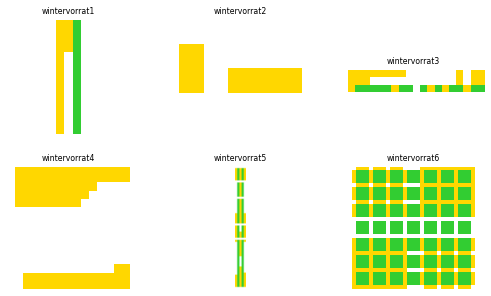

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


def zeichne_alle():
    farben = ListedColormap(['white', 'gold', 'limegreen'])
    plt.figure(figsize=(9, 5))
    for nr in range(1, 7):
        breite, hoehe, voegel = lies_wald(f'beispieldaten/wintervorrat{nr}.txt')
        besuche = simuliere(breite, hoehe, voegel)
        bild = []
        for y in range(1, hoehe + 1):          # y = 1 ist Süden: unten
            zeile = []
            for x in range(1, breite + 1):
                zeile.append(bewerte_feld(besuche[y][x])[0])
            bild.append(zeile)
        plt.subplot(2, 3, nr)
        plt.imshow(bild, cmap=farben, vmin=0, vmax=2, origin='lower')
        plt.title(f'wintervorrat{nr}', fontsize=8)
        plt.axis('off')
    plt.show()


zeichne_alle()